# 06 — Validation, Analysis and Final Results

**Goal:** check every stage of the pipeline in one place, show successes and failures honestly, and build the final per-call output required by the assessment.

**Runs on:** a laptop (no GPU needed). It reads the result files of notebooks 01–05.

**Before running:** fill in the manual review sheets `results/summary_review.csv` and `results/sentiment_review.csv` (columns `faithful`, `complete`, `label_correct`, `justification_supported`: write `yes` or `no`).

**Output**
- `results/calls.json` — the final result: one record per call (call_id, speakers, transcript, summary, sentiment, notes)
- `results/calls_overview.csv` — the same results as a flat table
- `results/figures/06_*.png` — charts used in the presentation

**Sections**
1. Setup
2. Transcription quality
3. Speaker labels
4. Summaries
5. Sentiment
6. A success and a failure, end to end
7. When the numbers can mislead
8. Final per-call output
9. Findings

## 1. Setup

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loading import RESULTS_DIR
from src.segmentation import format_conversation, role_from_content
from src.validation import build_call_record, rate_with_interval

REQUIRED = ["subset_ids.csv", "wer_summary.csv", "wer_per_call.csv", "asr_vad_experiment.csv", "asr_words.csv",
            "segmented_turns.csv", "summaries.csv", "summary_review.csv", "sentiment.csv", "sentiment_review.csv"]
missing = [f for f in REQUIRED if not (RESULTS_DIR / f).exists()]
assert not missing, f"Missing result files (run notebooks 01-05 first): {missing}"

load = lambda name: pd.read_csv(RESULTS_DIR / name)
subset, wer_summary, wer_per_call = load("subset_ids.csv"), load("wer_summary.csv"), load("wer_per_call.csv")
vad, asr_words, turns = load("asr_vad_experiment.csv"), load("asr_words.csv"), load("segmented_turns.csv")
summaries, summary_review = load("summaries.csv"), load("summary_review.csv")
sentiment, sentiment_review = load("sentiment.csv"), load("sentiment_review.csv")
turns["channel_index"] = turns["speaker"].str[-1].astype(int)       # "Speaker 1" -> channel 1

FIG_DIR = RESULTS_DIR / "figures"
COLORS = {"main": "#2E5C8A", "second": "#D9822B"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True})
pd.set_option("display.max_colwidth", 110)
print(f"Calls: {subset['call_id'].nunique()}  |  ASR model: {asr_words['asr_model'].iloc[0]}")

Calls: 25  |  ASR model: medium.en


## 2. Transcription quality

**Metric:** Word Error Rate (WER) against the human reference, after the same normalization on both sides (notebook 02).

In [2]:
wer_summary.round(4)

,scope,wer,ref_words,substitutions,deletions,insertions,n_pairs
0,final: overall,0.0490,2365,51,33,32,50
1,final: role: agent,0.0293,1467,22,15,6,25
2,final: role: caller,0.0813,898,29,18,26,25
3,first run: overall,0.0617,2365,49,69,28,50
4,first run: role: agent,0.0320,1467,23,17,7,25
5,first run: role: caller,0.1102,898,26,52,21,25
6,baseline (dataset ASR): overall,0.0748,2365,104,20,53,50
7,baseline (dataset ASR): agent,0.0688,1467,62,9,30,25
8,baseline (dataset ASR): caller,0.0846,898,42,11,23,25


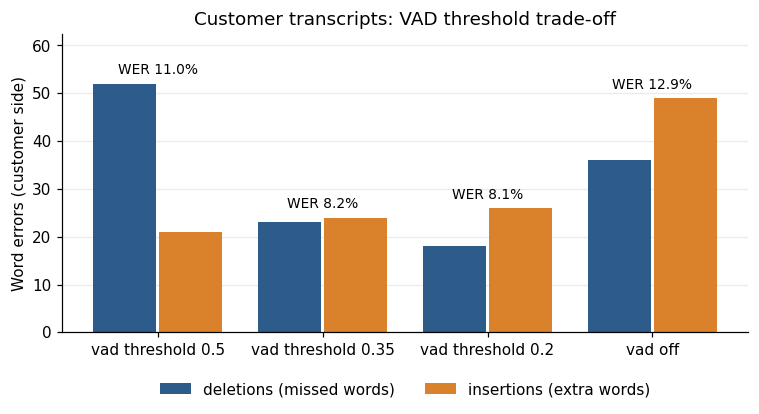

In [3]:
# The VAD trade-off: fewer deletions, but more insertions, as the threshold goes down
fig, ax = plt.subplots(figsize=(7, 3.9))
x = range(len(vad))
ax.bar([i - 0.2 for i in x], vad["deletions"], width=0.38, color=COLORS["main"], label="deletions (missed words)")
ax.bar([i + 0.2 for i in x], vad["insertions"], width=0.38, color=COLORS["second"], label="insertions (extra words)")
for i, row in vad.reset_index(drop=True).iterrows():
    ax.text(i, max(row["deletions"], row["insertions"]) + 2, f"WER {row['wer']:.1%}", ha="center", fontsize=9)
ax.set_xticks(list(x), vad["variant"])
ax.set_ylabel("Word errors (customer side)")
ax.set_title("Customer transcripts: VAD threshold trade-off")
ax.set_ylim(0, max(vad["deletions"].max(), vad["insertions"].max()) * 1.2)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "06_vad_tradeoff.png")
plt.show()

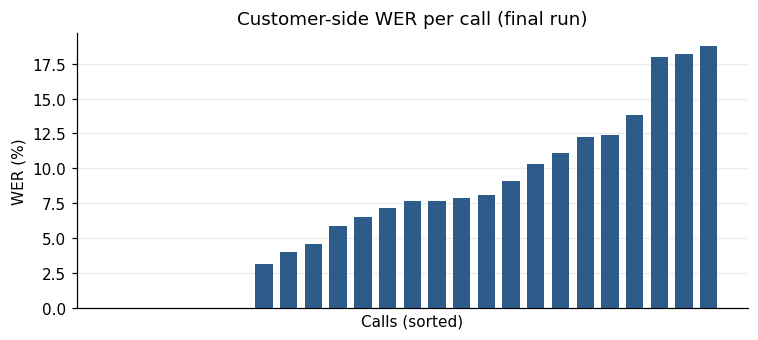

Median customer WER per call: 7.7%  |  calls above 15%: 3 of 25


In [4]:
# Per-call customer WER: most calls are accurate, a few are hard
customer_wer = wer_per_call[wer_per_call["speaker_role"] == "caller"].sort_values("wer")
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(range(len(customer_wer)), customer_wer["wer"] * 100, color=COLORS["main"], width=0.7)
ax.set_xticks([])
ax.set_xlabel("Calls (sorted)")
ax.set_ylabel("WER (%)")
ax.set_title("Customer-side WER per call (final run)")
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "06_customer_wer_per_call.png")
plt.show()
print(f"Median customer WER per call: {customer_wer['wer'].median():.1%}  |  calls above 15%: "
      f"{(customer_wer['wer'] > 0.15).sum()} of {len(customer_wer)}")

## 3. Speaker labels

- **Attribution:** share of recognized words that fall inside the same speaker's reference speech (notebook 02).
- **Role check:** does the content (who says the bank greeting) agree with the metadata roles?
- **Edge case:** the call with the agent on channel 1 must have Speaker 1 = Agent.

In [5]:
words = asr_words[asr_words["has_text"]]
attribution = words["in_own_speech"].mean()

guess = role_from_content(turns)
metadata_agent = turns[turns["role"] == "Agent"].groupby("call_id")["speaker"].first().str[-1].astype(int)
found = {c: ch for c, ch in guess.items() if ch is not None}
agree = sum(metadata_agent[c] == ch for c, ch in found.items())

edge = subset.loc[subset["agent_on_channel_1"], "call_id"].iloc[0]
edge_roles = turns[turns["call_id"] == edge].drop_duplicates("speaker").set_index("speaker")["role"].to_dict()

print(f"Words attributed to the right speaker: {attribution:.1%} of {len(words)}")
print(f"Role check: content found the agent in {len(found)} of {turns['call_id'].nunique()} calls; agrees in {agree} of {len(found)}")
print(f"Edge-case call {edge}: {edge_roles}")

Words attributed to the right speaker: 99.4% of 2251
Role check: content found the agent in 22 of 25 calls; agrees in 22 of 22
Edge-case call 7f3d383f8aff498d: {'Speaker 1': 'Agent', 'Speaker 2': 'Customer'}


## 4. Summaries

Automatic checks (notebook 04) and the manual review of 10 calls. With only 10 reviewed calls, the 95% confidence interval is wide: it shows how uncertain the rate is.

In [6]:
auto = pd.Series({
    "format OK": f"{summaries['parse_ok'].sum()}/{len(summaries)}",
    "issue matches the known task": f"{summaries['issue_matches_task'].sum()}/{len(summaries)}",
    "summaries with ungrounded numbers": f"{summaries['ungrounded_numbers'].fillna('').ne('').sum()}/{len(summaries)}",
    "manual: faithful": rate_with_interval(summary_review["faithful"]),
    "manual: complete": rate_with_interval(summary_review["complete"]),
})
auto.to_frame("result")

,result
format OK,25/25
issue matches the known task,25/25
summaries with ungrounded numbers,0/25
manual: faithful,"8/10 (80%, 95% CI 49%-94%)"
manual: complete,"9/10 (90%, 95% CI 60%-98%)"


In [7]:
# Summaries the reviewer marked as not faithful or not complete
flagged = summary_review[summary_review[["faithful", "complete"]].astype(str).apply(
    lambda col: col.str.strip().str.lower().eq("no")).any(axis=1)]
flagged[["call_id", "customer_issue", "agent_action", "outcome", "review_notes"]]

,call_id,customer_issue,agent_action,outcome,review_notes
2,663201e33f1a4e38,The customer wanted to transfer $147 from her savings account to her checking account.,The agent transferred $147 from the customer's savings to her checking account.,The call ended with the customer stating they were good and thanking the agent.,stating there were good but he didn’t thank him
7,9e05bd9ca9564089,The customer wanted to know the local branch hours.,The agent acknowledged the request and provided information about branch hours.,The call ended with the customer receiving branch hours information.,the call aren’t complete


## 5. Sentiment

Final label = language model (notebook 05). There are no human sentiment labels in the dataset, so agreement with the classifier or with the dataset's model-generated labels is **not accuracy**. The manual review is our best accuracy evidence.

In [8]:
label_counts = sentiment["sentiment"].value_counts().reindex(["negative", "neutral", "positive"], fill_value=0)
result = pd.Series({
    "labels (negative / neutral / positive)": " / ".join(map(str, label_counts.tolist())),
    "evidence is a real customer quote": f"{sentiment['evidence_is_customer_quote'].sum()}/{len(sentiment)}",
    "agrees with classifier": f"{(sentiment['sentiment'] == sentiment['classifier_label']).mean():.0%}",
    "agrees with dataset emotion label": f"{(sentiment['sentiment'] == sentiment['dataset_label']).mean():.0%}",
    "beginning -> end (classifier)": sentiment["start_to_end"].value_counts().to_dict(),
    "manual: label correct": rate_with_interval(sentiment_review["label_correct"]),
    "manual: justification supported": rate_with_interval(sentiment_review["justification_supported"]),
})
result.to_frame("result")

,result
labels (negative / neutral / positive),0 / 15 / 10
evidence is a real customer quote,24/25
agrees with classifier,64%
agrees with dataset emotion label,72%
beginning -> end (classifier),"{'same': 13, 'improved': 12}"
manual: label correct,"9/10 (90%, 95% CI 60%-98%)"
manual: justification supported,"9/10 (90%, 95% CI 60%-98%)"


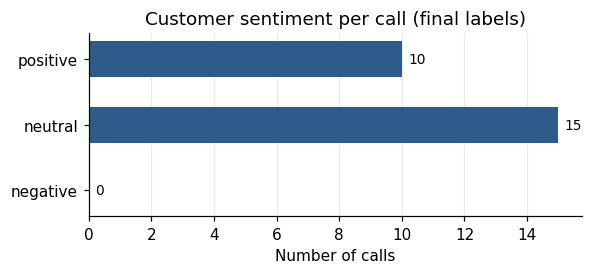

In [9]:
fig, ax = plt.subplots(figsize=(5.5, 2.6))
ax.barh(label_counts.index, label_counts.values, color=COLORS["main"], height=0.55)
for y, v in enumerate(label_counts.values):
    ax.text(v + 0.2, y, str(v), va="center", fontsize=9)
ax.set_title("Customer sentiment per call (final labels)")
ax.set_xlabel("Number of calls")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "06_sentiment_labels.png")
plt.show()

## 6. A success and a failure, end to end

One call where everything worked, and the hardest call for transcription, with transcript, summary and sentiment side by side.

In [10]:
customer_wer_by_call = customer_wer.set_index("call_id")["wer"]
success_id = customer_wer_by_call.idxmin()
failure_id = customer_wer_by_call.idxmax()

for label, call_id in [("SUCCESS", success_id), ("HARDEST CALL", failure_id)]:
    s = summaries.set_index("call_id").loc[call_id]
    t = sentiment.set_index("call_id").loc[call_id]
    print(f"===== {label}: {call_id}  (customer WER {customer_wer_by_call[call_id]:.1%}) =====")
    print(format_conversation(turns[turns["call_id"] == call_id]))
    print(f"\n  SUMMARY  issue: {s['customer_issue']}\n           action: {s['agent_action']}\n           outcome: {s['outcome']}")
    print(f"  SENTIMENT {t['sentiment']}: {t['justification']}  (evidence: \"{t['evidence']}\")\n")

===== SUCCESS: 09fc75fc02ea4b46  (customer WER 0.0%) =====
[   1.8s] Speaker 2 (Agent): Hello, this is Harper Valley National Bank. My name is John. How can I help you today?
[   9.7s] Speaker 1 (Customer): Hi, my name is Michael Jones. I need a new checkbook
[  16.4s] Speaker 2 (Agent): What is your address?
[  21.2s] Speaker 1 (Customer): my address is seven three four Main Street
[  35.2s] Speaker 2 (Agent): Mm -hmm
[  38.5s] Speaker 1 (Customer): Harper Valley Oregon Oh one three two five
[  55.2s] Speaker 2 (Agent): a New checkbook has been sent to your home address. Is there anything else I can help you with?
[  64.4s] Speaker 1 (Customer): No, that was it
[  65.5s] Speaker 2 (Agent): Thank you for calling. Have a great day
[  70.1s] Speaker 1 (Customer): You too. Thanks

  SUMMARY  issue: The customer needed a new checkbook.
           action: The agent confirmed the address and sent a new checkbook to the customer's home address.
           outcome: The call ended with the cust

## 7. When the numbers can mislead

- **Scripted data.** HarperValleyBank calls are role-play with a small vocabulary. WER on real call-center audio (accents, noise, long calls) would very likely be higher.
- **Tuned on the test set.** The VAD threshold was chosen on the same 25 calls it is evaluated on, so the final WER is slightly optimistic.
- **Small samples.** 25 calls, and 10 manually reviewed. A rate like 9/10 has a 95% interval of roughly 60%–98%.
- **Agreement is not accuracy.** The dataset's emotion labels come from another model, so matching them does not prove a label is right.
- **Class imbalance.** Most customers are neutral or polite. A model that always predicted "neutral" would still look accurate.
- **Automatic summary checks are weak.** They test format, the issue keyword and numbers; only the manual review tests whether the action and outcome are true.

## 8. Final per-call output

The assessment asks, for every call: `call_id`, speakers, transcript (segmented turns), summary (issue + action + outcome), sentiment (label + reason), and notes / limitations. We build that record for all 25 calls and **check** that every field is filled.

In [11]:
info = {"asr_model": asr_words["asr_model"].iloc[0]}
summaries_by_call = summaries.set_index("call_id")
sentiment_by_call = sentiment.set_index("call_id")

records = [
    build_call_record(call_id, turns[turns["call_id"] == call_id], summaries_by_call.loc[call_id],
                      sentiment_by_call.loc[call_id], wer_per_call[wer_per_call["call_id"] == call_id], info)
    for call_id in subset["call_id"]
]

# Completeness check: every required field is present and not empty
for r in records:
    assert r["speakers"] and r["transcript"], r["call_id"]
    assert all(r["summary"].values()), r["call_id"]
    assert r["sentiment"]["label"] and r["sentiment"]["justification"], r["call_id"]
    assert r["notes"], r["call_id"]

(RESULTS_DIR / "calls.json").write_text(json.dumps(records, indent=2, ensure_ascii=False))

overview = pd.DataFrame([{
    "call_id": r["call_id"],
    "speakers": "; ".join(f"{k} = {v}" for k, v in r["speakers"].items()),
    "turns": len(r["transcript"]),
    "customer_issue": r["summary"]["customer_issue"],
    "agent_action": r["summary"]["agent_action"],
    "outcome": r["summary"]["outcome"],
    "sentiment": r["sentiment"]["label"],
    "sentiment_reason": r["sentiment"]["justification"],
    "beginning_to_end": r["sentiment"]["change"],
    "notes": " | ".join(r["notes"]),
} for r in records])
overview.to_csv(RESULTS_DIR / "calls_overview.csv", index=False)

print(f"All {len(records)} calls complete. Saved results/calls.json and results/calls_overview.csv")
print(json.dumps(records[0], indent=2)[:1500], "...")

All 25 calls complete. Saved results/calls.json and results/calls_overview.csv
{
  "call_id": "08f360b3f3b844ef",
  "speakers": {
    "Speaker 1": "Customer",
    "Speaker 2": "Agent"
  },
  "transcript": [
    {
      "turn": 1,
      "speaker": "Speaker 2",
      "role": "Agent",
      "start_s": 1.84,
      "end_s": 7.26,
      "text": "Hello, this is Harbor Valley National Bank. My name is Robert. How can I help you today?"
    },
    {
      "turn": 2,
      "speaker": "Speaker 1",
      "role": "Customer",
      "start_s": 10.89,
      "end_s": 14.59,
      "text": "Hi. My name is Linda Smith. I need to check my account balance."
    },
    {
      "turn": 3,
      "speaker": "Speaker 2",
      "role": "Agent",
      "start_s": 14.5,
      "end_s": 24.04,
      "text": "Sure, I'd be happy to do that for you. And what's your name, please? Oh, right, it's Linda Smith. Sorry about that. Linda Smith, right."
    },
    {
      "turn": 4,
      "speaker": "Speaker 1",
      "role": "C

## 9. Findings

Pipeline quality at a glance

Transcription: WER 4.9% overall (agent 2.9%, customer 8.1%), better than the dataset's own ASR (7.5%).
Speakers: 99.4% of recognized words fall inside the same speaker's reference speech; the content-based role check agreed with the metadata in every call where it could decide; the edge-case call (agent on channel 1) is labelled correctly.
Summaries: automatic checks passed on 25/25; manual review found 8/10 faithful and 9/10 complete.
Sentiment: manual review found 9/10 labels correct; evidence quotes are real customer words in 24/25 calls.
Final output: all 25 calls have every required field in results/calls.json.

Main risks found

Quiet customer audio can be dropped by the voice activity detector (fixed by lowering its threshold).
The summarization model can invent a typical ending when a call is incomplete.
The sentiment model is not fully consistent on polite closing phrases.

How far the numbers can be trusted

Scripted role-play data, 25 calls, 10 manually reviewed, and one setting tuned on the evaluation calls: the results show the pipeline works, but are not precise estimates for real call-center audio.